# HAR Clustering — Part 1

**Owner:** Clustering teammate 1

This half covers dataset loading/audit, feature preparation, K-Means elbow selection, fitting the required clustering algorithms, and core clustering metrics. Run this notebook from top to bottom.

# Machine Learning Capstone — Review 2
## Clustering Track — Human Activity Recognition with Smartphones

This notebook follows the same clean, section-by-section style as the classification notebook: dataset loading and audit, preprocessing, algorithm fitting, comparison table, visualisations, and interpretation.

**Rubric algorithms**
1. K-Means Clustering — choose `k` using an Elbow curve.
2. Agglomerative Hierarchical Clustering — show a dendrogram and compare linkage strategies.

**Important:** `Activity` and `subject` are metadata. They are excluded from clustering. The ground-truth `Activity` labels are used only after fitting, to interpret/validate the clusters.

# Machine Learning Capstone — Review 2
## Clustering Track — Human Activity Recognition with Smartphones

This notebook follows the same clean, section-by-section style as the classification notebook: dataset loading and audit, preprocessing, algorithm fitting, comparison table, visualisations, and interpretation.

**Rubric algorithms**
1. K-Means Clustering — choose `k` using an Elbow curve.
2. Agglomerative Hierarchical Clustering — show a dendrogram and compare linkage strategies.

**Important:** `Activity` and `subject` are metadata. They are excluded from clustering. The ground-truth `Activity` labels are used only after fitting, to interpret/validate the clusters.

In [1]:
# 1. Imports and reproducibility
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)
warnings.filterwarnings("ignore", category=UserWarning)

# CSV is expected beside this notebook.
DATA_PATH = Path("test.csv")

## 2. Load the dataset
Load the provided HAR smartphone feature table.

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Couldn't find {DATA_PATH.resolve()}. Put test.csv beside the notebook "
        "or update DATA_PATH."
    )

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())
print("\\nColumns at the end:", df.columns[-5:].tolist())

Shape: (2947, 563)


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",subject,Activity
0,0.257178,-0.023285,-0.014654,-0.938404,-0.920091,-0.667683,-0.952501,-0.925249,-0.674302,-0.894088,...,-0.705974,0.006462,0.162920,-0.825886,0.271151,-0.720009,0.276801,-0.057978,2,STANDING
1,0.286027,-0.013163,-0.119083,-0.975415,-0.967458,-0.944958,-0.986799,-0.968401,-0.945823,-0.894088,...,-0.594944,-0.083495,0.017500,-0.434375,0.920593,-0.698091,0.281343,-0.083898,2,STANDING
2,0.275485,-0.026050,-0.118152,-0.993819,-0.969926,-0.962748,-0.994403,-0.970735,-0.963483,-0.939260,...,-0.640736,-0.034956,0.202302,0.064103,0.145068,-0.702771,0.280083,-0.079346,2,STANDING
3,0.270298,-0.032614,-0.117520,-0.994743,-0.973268,-0.967091,-0.995274,-0.974471,-0.968897,-0.938610,...,-0.736124,-0.017067,0.154438,0.340134,0.296407,-0.698954,0.284114,-0.077108,2,STANDING
4,0.274833,-0.027848,-0.129527,-0.993852,-0.967445,-0.978295,-0.994111,-0.965953,-0.977346,-0.938610,...,-0.846595,-0.002223,-0.040046,0.736715,-0.118545,-0.692245,0.290722,-0.073857,2,STANDING


\nColumns at the end: ['angle(X,gravityMean)', 'angle(Y,gravityMean)', 'angle(Z,gravityMean)', 'subject', 'Activity']


## 3. Dataset audit
Inspect missing values, duplicates, and activity distribution. These are descriptive checks; activity labels are not used to fit clusters.

In [3]:
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

if "Activity" in df.columns:
    display(df["Activity"].value_counts().to_frame("count"))
elif "activity" in df.columns:
    display(df["activity"].value_counts().to_frame("count"))
else:
    print("No Activity label column found; post-clustering activity interpretation will be skipped.")

Missing values: 0
Duplicate rows: 0


,count
Activity,
LAYING,537
STANDING,532
WALKING,496
SITTING,491
WALKING_UPSTAIRS,471
WALKING_DOWNSTAIRS,420


## 4. Prepare features
The HAR CSV commonly contains numerical sensor-derived features plus `Activity` and `subject` metadata. We drop metadata from the feature matrix. Scaling is applied because clustering uses distances; the scaler is fitted only on the feature matrix used for clustering.

In [4]:
# Detect Activity label without assuming capitalization.
activity_col = next((c for c in df.columns if c.lower() == "activity"), None)
subject_col = next((c for c in df.columns if c.lower() == "subject"), None)

activity_labels = df[activity_col].copy() if activity_col else None
metadata_cols = [c for c in [activity_col, subject_col] if c is not None]

X_raw = df.drop(columns=metadata_cols, errors="ignore")
X_raw = X_raw.select_dtypes(include=np.number)
X_raw = X_raw.replace([np.inf, -np.inf], np.nan)
X_raw = X_raw.fillna(X_raw.median(numeric_only=True))

if X_raw.empty:
    raise ValueError("No numeric feature columns found after excluding metadata.")

scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(X_raw),
    columns=X_raw.columns,
    index=X_raw.index
)

print("Feature matrix:", X_scaled.shape)
print("Activity labels excluded from fitting:", activity_col is not None)
display(X_scaled.iloc[:5, :8])

Feature matrix: (2947, 561)
Activity labels excluded from fitting: True


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y
0,-0.277708,-0.210631,2.193076,-0.787267,-0.833212,-0.093444,-0.808091,-0.839013
1,0.198660,0.182591,-0.250264,-0.876984,-0.929061,-0.858050,-0.897145,-0.928949
2,0.024587,-0.318055,-0.228485,-0.921598,-0.934054,-0.907107,-0.916891,-0.933813
3,-0.061057,-0.573037,-0.213709,-0.923837,-0.940817,-0.919082,-0.919152,-0.941599
4,0.013823,-0.387881,-0.494639,-0.921679,-0.929036,-0.949979,-0.916133,-0.923846


## 5. K-Means — Elbow method

The elbow curve shows how the within-cluster sum of squared distances changes as the number of clusters increases. The value of `k` is selected from the point where the reduction in inertia begins to level off.


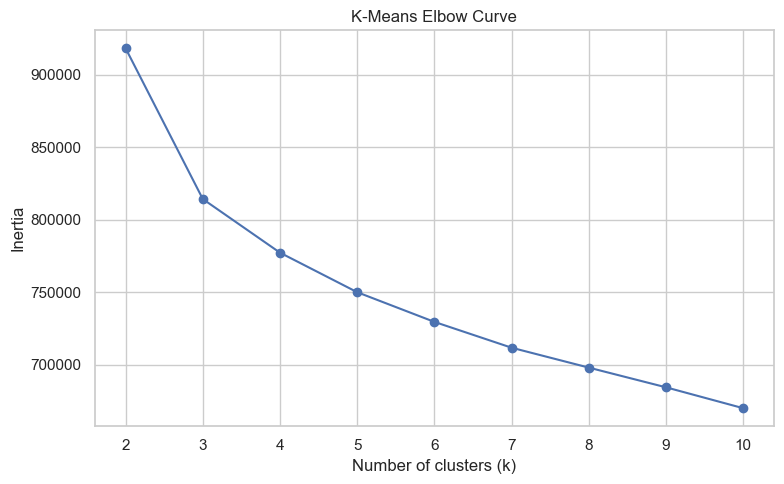

Chosen k: 6


In [5]:
K_MIN, K_MAX = 2, 10
k_values = list(range(K_MIN, K_MAX + 1))
inertias = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker="o")
plt.title("K-Means Elbow Curve")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.xticks(k_values)
plt.tight_layout()
plt.show()

chosen_k = 6
print("Chosen k:", chosen_k)

## 6. Fit the two required clustering algorithms
Both algorithms are fitted on the same scaled feature matrix and use the same chosen number of clusters for a fair comparison.

In [6]:
kmeans_model = KMeans(
    n_clusters=chosen_k,
    random_state=RANDOM_STATE,
    n_init=10
)
kmeans_labels = kmeans_model.fit_predict(X_scaled)

# Ward is the primary hierarchical model; alternative linkage methods
# are compared in Section 8.
hierarchical_model = AgglomerativeClustering(
    n_clusters=chosen_k,
    linkage="ward"
)
hierarchical_labels = hierarchical_model.fit_predict(X_scaled)

print("K-Means cluster sizes:")
display(pd.Series(kmeans_labels).value_counts().sort_index().to_frame("samples"))

print("Agglomerative (Ward) cluster sizes:")
display(pd.Series(hierarchical_labels).value_counts().sort_index().to_frame("samples"))

K-Means cluster sizes:


,samples
0,226
1,722
2,664
3,499
4,456
5,380


Agglomerative (Ward) cluster sizes:


,samples
0,1010
1,612
2,300
3,519
4,475
5,31


## 7. Required evaluation metrics
Report Silhouette Score (higher is better), Davies-Bouldin Index (lower is better), and Calinski-Harabasz Index (higher is better) for both required algorithms.

In [7]:
def clustering_metrics(X, labels):
    # Internal metrics require at least 2 clusters and fewer clusters than samples.
    n_clusters = len(np.unique(labels))
    if n_clusters < 2 or n_clusters >= len(X):
        return np.nan, np.nan, np.nan
    return (
        silhouette_score(X, labels),
        davies_bouldin_score(X, labels),
        calinski_harabasz_score(X, labels)
    )

results = []
for algorithm, labels in [
    ("K-Means", kmeans_labels),
    ("Agglomerative (Ward)", hierarchical_labels)
]:
    silhouette, db_index, ch_index = clustering_metrics(X_scaled, labels)
    results.append({
        "Algorithm": algorithm,
        "Clusters": len(np.unique(labels)),
        "Silhouette Score (higher is better)": silhouette,
        "Davies-Bouldin Index (lower is better)": db_index,
        "Calinski-Harabasz Index (higher is better)": ch_index
    })

clustering_results = pd.DataFrame(results)
display(clustering_results.round(4))
clustering_results.to_csv("clustering_comparison.csv", index=False)

,Algorithm,Clusters,Silhouette Score (higher is better),Davies-Bouldin Index (lower is better),Calinski-Harabasz Index (higher is better)
0,K-Means,6,0.103,2.6595,744.8089
1,Agglomerative (Ward),6,0.097,2.5856,705.1731
